# 03 Drivers of customer value and cancellation (BQ3): R version

**BQ3:** Which factors relate to customer value and to order cancellation?

- **Part A, customer value:** which Year 1 behaviours predict a customer's net revenue in Year 2?
- **Part B, cancellation:** which order-line characteristics predict that a line is later cancelled?

Same questions, data and definitions as `03_drivers_py.ipynb`; the regression results must agree.
See the Python notebook for the full description of features and design.

## Setup and data

In [10]:
suppressPackageStartupMessages({
  library(arrow); library(dplyr); library(tidyr); library(ggplot2); library(scales)
  library(sandwich); library(lmtest); library(rpart); library(rpart.plot); library(pROC)
})
options(dplyr.summarise.inform = FALSE, scipen = 999, digits = 4,
        repr.plot.width = 11, repr.plot.height = 4)
Sys.setenv(TZ = "UTC")

root <- if (dir.exists("data")) "." else ".."
proc <- file.path(root, "data", "processed")
fig  <- file.path(root, "reports", "figures")
dir.create(fig, showWarnings = FALSE, recursive = TRUE)

Y2_START <- as.POSIXct("2010-12-01", tz = "UTC")
Y2_END   <- as.POSIXct("2011-12-01", tz = "UTC")

read_tbl <- function(name) {
  read_parquet(file.path(proc, paste0(name, ".parquet"))) |>
    mutate(across(c(date, week_start, month), as.Date))
}
sales   <- read_tbl("sales_clean")
cancels <- read_tbl("cancellations")
prod <- sales   |> filter(line_type == "product")      # T6
canc <- cancels |> filter(line_type == "product")      # T5
cat(sprintf("Product sales lines: %s   with a customer: %.1f%%\n",
            comma(nrow(prod)), 100 * mean(prod$has_customer)))

Product sales lines: 1,003,357   with a customer: 77.4%


# Part A: Customer value
Features from Year 1 (Dec 2009 – Nov 2010); outcome = net revenue in Year 2 (Dec 2010 – Nov 2011).

In [11]:
y1 <- prod |> filter(has_customer, invoice_date < Y2_START)
y2 <- prod |> filter(has_customer, invoice_date >= Y2_START, invoice_date < Y2_END)
c1 <- canc |> filter(!is.na(customer_id), invoice_date < Y2_START)
c2 <- canc |> filter(!is.na(customer_id), invoice_date >= Y2_START, invoice_date < Y2_END)

feat <- y1 |>
  group_by(customer_id) |>
  summarise(first_buy = min(invoice_date), last_buy = max(invoice_date),
            frequency = n_distinct(date), variety = n_distinct(stock_code),
            gross_y1 = sum(revenue), uk_share = mean(is_uk)) |>
  left_join(y1 |> filter(!cancelled_exact) |> group_by(customer_id) |>
              summarise(kept_sales = sum(revenue), orders = n_distinct(invoice)), by = "customer_id") |>
  left_join(c1 |> group_by(customer_id) |> summarise(cancel_y1 = -sum(revenue)), by = "customer_id") |>
  left_join(y2 |> group_by(customer_id) |> summarise(gross_y2 = sum(revenue)), by = "customer_id") |>
  left_join(c2 |> group_by(customer_id) |> summarise(cancel_y2 = -sum(revenue)), by = "customer_id") |>
  mutate(cancel_y1       = coalesce(cancel_y1, 0),
         recency_days    = floor(as.numeric(difftime(Y2_START, last_buy, units = "days"))),
         tenure_days     = floor(as.numeric(difftime(Y2_START, first_buy, units = "days"))),
         avg_order_value = kept_sales / orders,
         cancel_share    = pmin(cancel_y1 / gross_y1, 1),
         is_uk           = as.integer(uk_share >= 0.5),
         value_y2        = pmax(coalesce(gross_y2, 0) - coalesce(cancel_y2, 0), 0))

before <- nrow(feat)
feat <- feat |> filter(!is.na(avg_order_value))     # customers whose every order was cancelled
cat(sprintf("Year 1 customers: %s   used: %s (dropped %d with no kept orders)\n",
            comma(before), comma(nrow(feat)), before - nrow(feat)))
cat(sprintf("Bought again in Year 2: %.1f%%\n", 100 * mean(feat$value_y2 > 0)))
cat(sprintf("Year 2 net revenue per customer: median £%s, mean £%s\n",
            comma(round(median(feat$value_y2))), comma(round(mean(feat$value_y2)))))

Year 1 customers: 4,239   used: 4,227 (dropped 12 with no kept orders)
Bought again in Year 2: 63.8%
Year 2 net revenue per customer: median £308, mean £1,544


## A1. Correlation (Spearman)

                recency_days frequency avg_order_value variety tenure_days
recency_days            1.00     -0.49           -0.15   -0.41        0.12
frequency              -0.49      1.00            0.20    0.65        0.58
avg_order_value        -0.15      0.20            1.00    0.43        0.08
variety                -0.41      0.65            0.43    1.00        0.34
tenure_days             0.12      0.58            0.08    0.34        1.00
cancel_share           -0.17      0.42            0.17    0.29        0.27
is_uk                   0.01      0.03           -0.18   -0.04        0.04
value_y2               -0.43      0.57            0.37    0.48        0.24
                cancel_share is_uk value_y2
recency_days           -0.17  0.01    -0.43
frequency               0.42  0.03     0.57
avg_order_value         0.17 -0.18     0.37
variety                 0.29 -0.04     0.48
tenure_days             0.27  0.04     0.24
cancel_share            1.00 -0.04     0.28
is_uk            

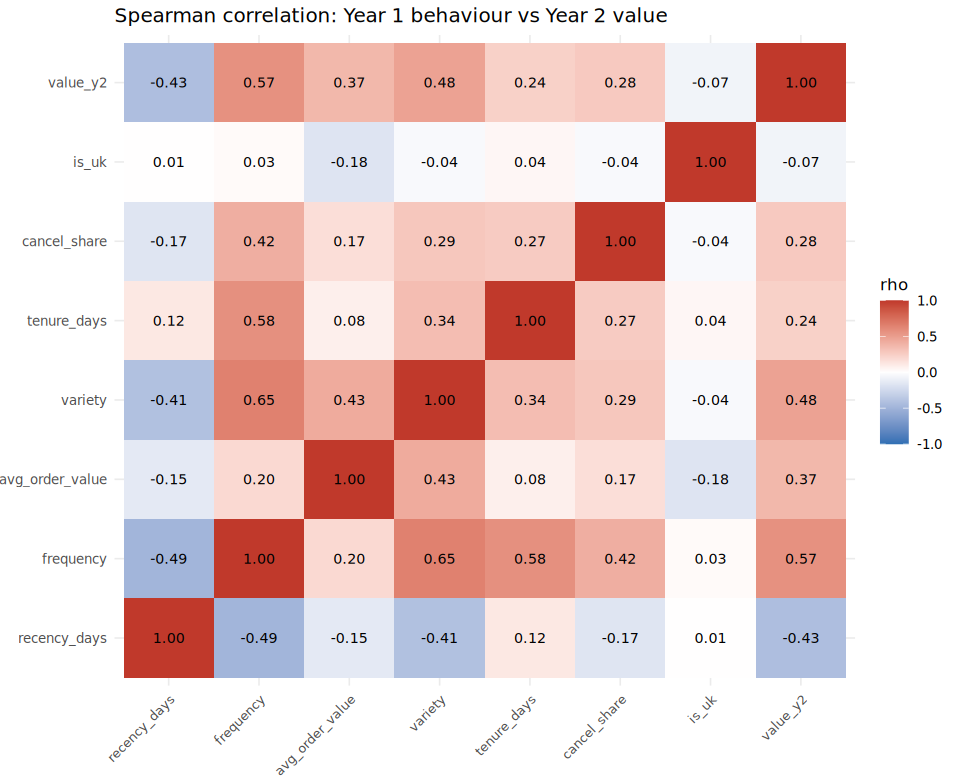

In [12]:
cols <- c("recency_days", "frequency", "avg_order_value", "variety",
          "tenure_days", "cancel_share", "is_uk", "value_y2")
corr <- cor(feat[cols], method = "spearman")
print(round(corr, 2))

corr_long <- as.data.frame(as.table(corr))
names(corr_long) <- c("row", "col", "rho")
p_corr <- ggplot(corr_long, aes(col, row, fill = rho)) +
  geom_tile() +
  geom_text(aes(label = sprintf("%.2f", rho)), size = 3) +
  scale_fill_gradient2(low = "#2F6FB3", mid = "white", high = "#C0392B", limits = c(-1, 1)) +
  labs(title = "Spearman correlation: Year 1 behaviour vs Year 2 value", x = NULL, y = NULL) +
  theme_minimal(base_size = 10) + theme(axis.text.x = element_text(angle = 45, hjust = 1))
ggsave(file.path(fig, "bq3_correlation_r.png"), p_corr, width = 8, height = 6.5, dpi = 150)
options(repr.plot.width = 8, repr.plot.height = 6.5); p_corr

## A2. Predictors and multicollinearity (VIF)
Predictors with VIF above 10 are removed one at a time, highest first.

In [13]:
m <- tibble(
  recency      = log1p(feat$recency_days),
  frequency    = log(feat$frequency),
  order_value  = log(feat$avg_order_value),
  variety      = log(feat$variety),
  tenure       = feat$tenure_days,
  cancel_share = feat$cancel_share
) |>
  mutate(across(everything(), ~ (.x - mean(.x)) / sd(.x))) |>      # standardise
  mutate(is_uk = feat$is_uk, log_value_y2 = log1p(feat$value_y2))

vif_table <- function(cols) {
  sapply(cols, function(v) {
    r2 <- summary(lm(reformulate(setdiff(cols, v), v), data = m))$r.squared
    1 / (1 - r2)
  })
}

predictors <- c("recency", "frequency", "order_value", "variety", "tenure", "cancel_share", "is_uk")
cat("VIF, all predictors:\n"); print(round(vif_table(predictors), 2))
removed <- c()
repeat {
  v <- vif_table(predictors)
  if (max(v) <= 10) break
  removed <- c(removed, names(which.max(v)))
  predictors <- setdiff(predictors, names(which.max(v)))
}
cat("\nRemoved for multicollinearity:", if (length(removed)) removed else "none", "\n")
cat("VIF, final predictors:\n"); print(round(vif_table(predictors), 2))

VIF, all predictors:


     recency    frequency  order_value      variety       tenure cancel_share 
        2.00         3.37         1.34         2.01         2.18         1.02 
       is_uk 
        1.05 

Removed for multicollinearity: none 
VIF, final predictors:
     recency    frequency  order_value      variety       tenure cancel_share 
        2.00         3.37         1.34         2.01         2.18         1.02 
       is_uk 
        1.05 


## A3. Linear regression with robust (HC3) standard errors
`df = Inf` reports z-tests, matching Python.

In [14]:
ols <- lm(reformulate(predictors, "log_value_y2"), data = m)
rob <- coeftest(ols, vcov = vcovHC(ols, type = "HC3"), df = Inf)
coef_tbl <- data.frame(coef = round(rob[, 1], 3), robust_se = round(rob[, 2], 3),
                       p_value = round(rob[, 4], 3))[-1, ]
coef_tbl$effect_per_sd <- sprintf("%+.1f%%", 100 * (exp(rob[-1, 1]) - 1))
print(coef_tbl)
cat(sprintf("\nCustomers: %s   R-squared: %.3f   adjusted: %.3f\n",
            comma(nobs(ols)), summary(ols)$r.squared, summary(ols)$adj.r.squared))

               coef robust_se p_value effect_per_sd
recency      -0.457     0.062   0.000        -36.7%
frequency     1.531     0.079   0.000       +362.3%
order_value   0.605     0.055   0.000        +83.2%
variety       0.079     0.064   0.218         +8.2%
tenure       -0.185     0.063   0.003        -16.9%
cancel_share -0.008     0.051   0.876         -0.8%
is_uk        -0.430     0.168   0.010        -35.0%

Customers: 4,227   R-squared: 0.347   adjusted: 0.346


# Part B: Cancellation
Target: order line later cancelled with an exact match (T5). Train on Year 1, test on Year 2.

In [15]:
lines <- prod |>
  filter(has_customer, invoice_date < Y2_END) |>
  group_by(invoice) |> mutate(basket_lines = n()) |> ungroup()

invoices <- lines |>
  group_by(customer_id, invoice) |>
  summarise(first_time = min(invoice_date), .groups = "drop") |>
  arrange(customer_id, first_time, invoice) |>
  group_by(customer_id) |> mutate(prior_orders = row_number() - 1) |> ungroup()

lines <- lines |>
  left_join(invoices |> select(invoice, prior_orders), by = "invoice") |>
  mutate(cancelled        = as.integer(cancelled_exact),
         log_qty          = log(quantity),
         log_price        = log(price),
         log_basket       = log(basket_lines),
         log_prior_orders = log1p(prior_orders),
         is_uk            = as.integer(is_uk),
         q4               = as.integer(as.integer(format(invoice_date, "%m")) %in% 10:12),
         late_hour        = as.integer(hour >= 16),
         is_price_outlier = as.integer(is_price_outlier))

features <- c("log_qty", "log_price", "log_basket", "log_prior_orders",
              "is_uk", "q4", "late_hour", "is_price_outlier")
train <- lines |> filter(invoice_date < Y2_START)
test  <- lines |> filter(invoice_date >= Y2_START)
cat(sprintf("Train (Year 1): %s lines, cancel rate %.2f%%\n", comma(nrow(train)), 100 * mean(train$cancelled)))
cat(sprintf("Test  (Year 2): %s lines, cancel rate %.2f%%\n", comma(nrow(test)),  100 * mean(test$cancelled)))

Train (Year 1): 385,443 lines, cancel rate 0.88%
Test  (Year 2): 374,189 lines, cancel rate 0.74%


## B1. Logistic regression
Odds ratios with Wald 95% intervals (the same method as Python's statsmodels).

In [16]:
performance <- function(y, score) {
  r <- roc(y, score, levels = c(0, 1), direction = "<", quiet = TRUE)
  auc_v <- as.numeric(auc(r))
  c(auc = auc_v, gini = 2 * auc_v - 1, ks = max(r$sensitivities + r$specificities - 1))
}

logit <- glm(reformulate(features, "cancelled"), data = train, family = binomial)
ci <- exp(confint.default(logit))
odds <- data.frame(odds_ratio = exp(coef(logit)), ci_low = ci[, 1], ci_high = ci[, 2],
                   p_value = summary(logit)$coefficients[, 4])[-1, ]
print(round(odds, 3))

p_logit <- predict(logit, newdata = test, type = "response")
perf_l <- performance(test$cancelled, p_logit)
cat(sprintf("\nLogistic regression, Year 2 test: AUC %.3f   Gini %.3f   KS %.3f\n",
            perf_l["auc"], perf_l["gini"], perf_l["ks"]))

                 odds_ratio ci_low ci_high p_value
log_qty               1.091  1.054   1.130   0.000
log_price             1.644  1.572   1.719   0.000
log_basket            0.654  0.628   0.681   0.000
log_prior_orders      1.012  0.984   1.042   0.399
is_uk                 0.513  0.465   0.566   0.000
q4                    0.796  0.739   0.857   0.000
late_hour             1.154  1.044   1.275   0.005
is_price_outlier     17.788 13.007  24.326   0.000

Logistic regression, Year 2 test: AUC 0.677   Gini 0.355   KS 0.261


## B2. Decision tree
Depth 3, at least 500 lines per leaf; equal class priors play the role of Python's balanced class weights. Trees from different libraries can split slightly differently, so small differences from Python are expected.

Decision tree, Year 2 test: AUC 0.631   Gini 0.262   KS 0.201

n= 385443 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

 1) root 385443 192700.0 0 (0.5000 0.5000)  
   2) log_price< 1.59 314718 119300.0 0 (0.5693 0.4307)  
     4) log_basket>=3.45 170681  38320.0 0 (0.6912 0.3088)  
       8) log_qty< 4.844 169596  35180.0 0 (0.7079 0.2921) *
       9) log_qty>=4.844 1085    519.5 1 (0.1419 0.8581) *
     5) log_basket< 3.45 144037  71940.0 1 (0.4705 0.5295)  
      10) is_uk>=0.5 131890  65380.0 0 (0.5022 0.4978) *
      11) is_uk< 0.5 12147   5989.0 1 (0.2776 0.7224) *
   3) log_price>=1.59 70725  35030.0 1 (0.3229 0.6771)  
     6) log_price< 2.187 53433  26580.0 1 (0.3848 0.6152)  
      12) log_basket>=3.651 20004   9980.0 1 (0.4450 0.5550) *
      13) log_basket< 3.651 33429  16600.0 1 (0.3559 0.6441) *
     7) log_price>=2.187 17292   8449.0 1 (0.2144 0.7856)  
      14) log_qty>=0.3466 10026   4936.0 1 (0.2648 0.7352) *
      15) log_qty< 0.3466 7266   35

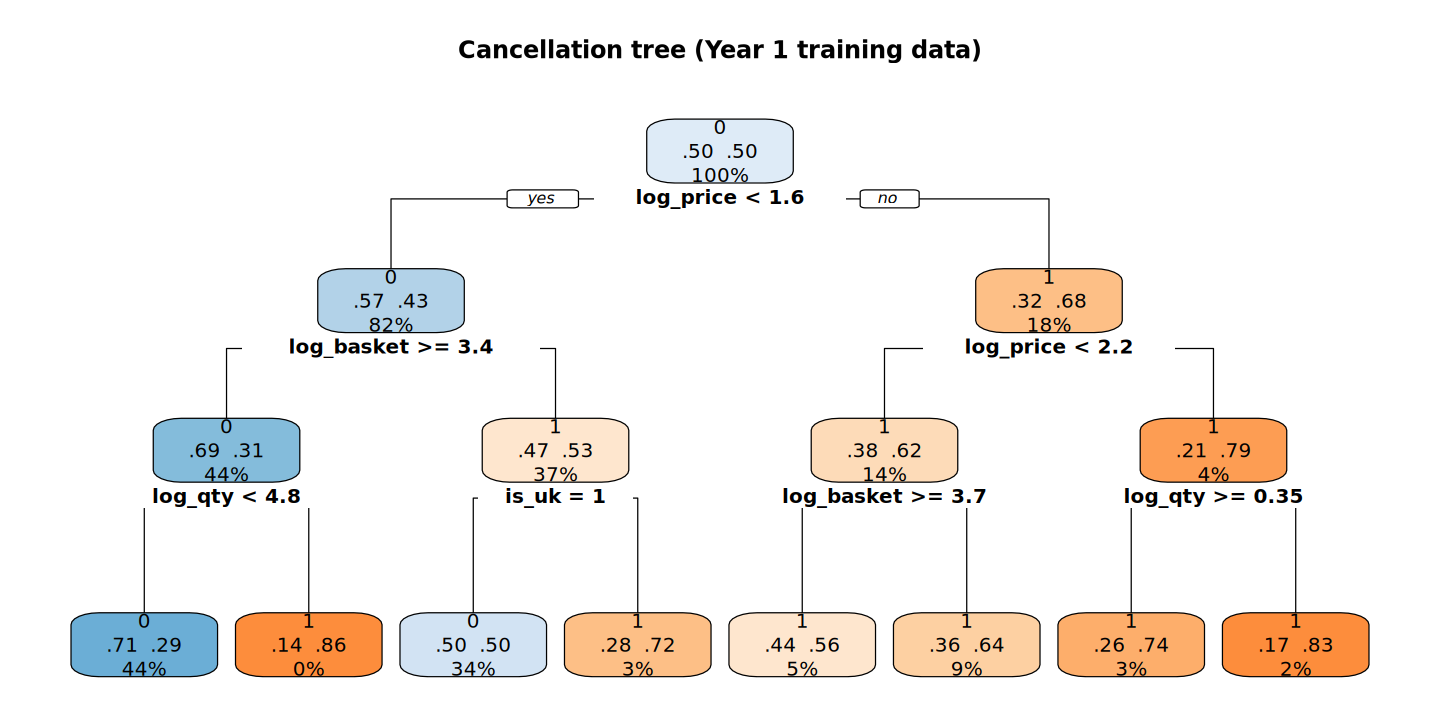

In [17]:
tree <- rpart(reformulate(features, "factor(cancelled)"), data = train, method = "class",
              parms = list(prior = c(0.5, 0.5)),
              control = rpart.control(maxdepth = 3, minbucket = 500, minsplit = 1000, cp = -1, xval = 0))
p_tree <- predict(tree, newdata = test, type = "prob")[, 2]
perf_t <- performance(test$cancelled, p_tree)
cat(sprintf("Decision tree, Year 2 test: AUC %.3f   Gini %.3f   KS %.3f\n\n",
            perf_t["auc"], perf_t["gini"], perf_t["ks"]))
print(tree)

leaves <- train |>
  mutate(node = as.integer(rownames(tree$frame))[tree$where]) |>
  group_by(node) |>
  summarise(lines = n(), cancel_rate = mean(cancelled)) |>
  arrange(desc(cancel_rate))
print(leaves)
cat("\nVariable importance:\n"); print(round(tree$variable.importance / sum(tree$variable.importance), 3))

options(repr.plot.width = 12, repr.plot.height = 6)
rpart.plot(tree, type = 2, extra = 104, box.palette = "BuOr", main = "Cancellation tree (Year 1 training data)")
png(file.path(fig, "bq3_cancellation_tree_r.png"), width = 1800, height = 900, res = 150)
rpart.plot(tree, type = 2, extra = 104, box.palette = "BuOr"); invisible(dev.off())

## B3. Comparing the models

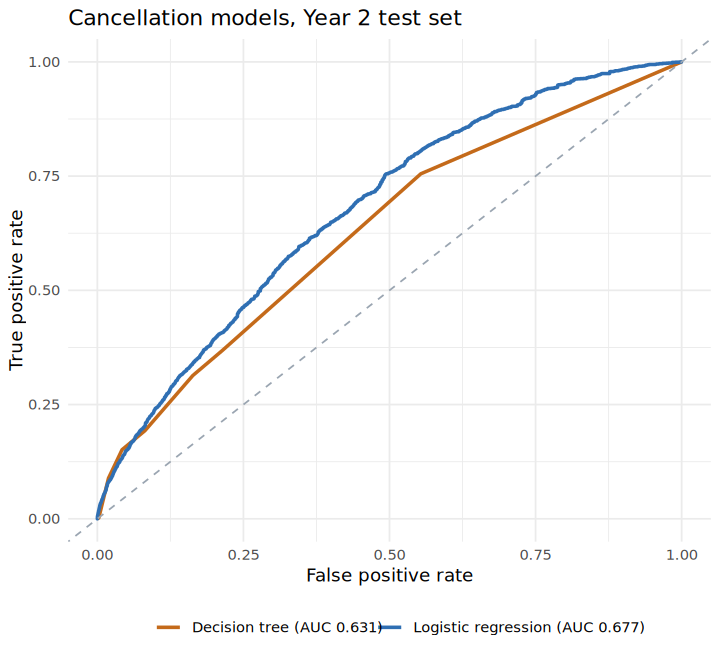

In [18]:
roc_df <- bind_rows(
  { r <- roc(test$cancelled, p_logit, levels = c(0, 1), direction = "<", quiet = TRUE)
    data.frame(model = sprintf("Logistic regression (AUC %.3f)", perf_l["auc"]),
               fpr = 1 - r$specificities, tpr = r$sensitivities) },
  { r <- roc(test$cancelled, p_tree, levels = c(0, 1), direction = "<", quiet = TRUE)
    data.frame(model = sprintf("Decision tree (AUC %.3f)", perf_t["auc"]),
               fpr = 1 - r$specificities, tpr = r$sensitivities) })
p_roc <- ggplot(roc_df, aes(fpr, tpr, colour = model)) +
  geom_line(linewidth = 1) +
  geom_abline(linetype = "dashed", colour = "#9AA5B1") +
  scale_colour_manual(values = c("#C46A1A", "#2F6FB3"), name = NULL) +
  labs(title = "Cancellation models, Year 2 test set",
       x = "False positive rate", y = "True positive rate") +
  theme_minimal(base_size = 11) + theme(legend.position = "bottom")
ggsave(file.path(fig, "bq3_roc_r.png"), p_roc, width = 6, height = 5.5, dpi = 150)
options(repr.plot.width = 6, repr.plot.height = 5.5); p_roc